In [59]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### Task 1

Постройте на одном графике столбцы месячной выручки и линию месячных рекламных расходов; значения заданы в миллионах. Используйте передаваемый объект осей matplotlib, чтобы совместить графики.

Предполагаются импорты import pandas as pd и import numpy as np.

In [60]:
df = pd.DataFrame({"revenue":[57,68,63,71,72,90,80,62,59,51,47,52],
                   "advertising":[2.1,1.9,2.7,3.0,3.6,3.2,2.7,2.4,1.8,1.6,1.3,1.9],
                   "month":range(12)
                  })

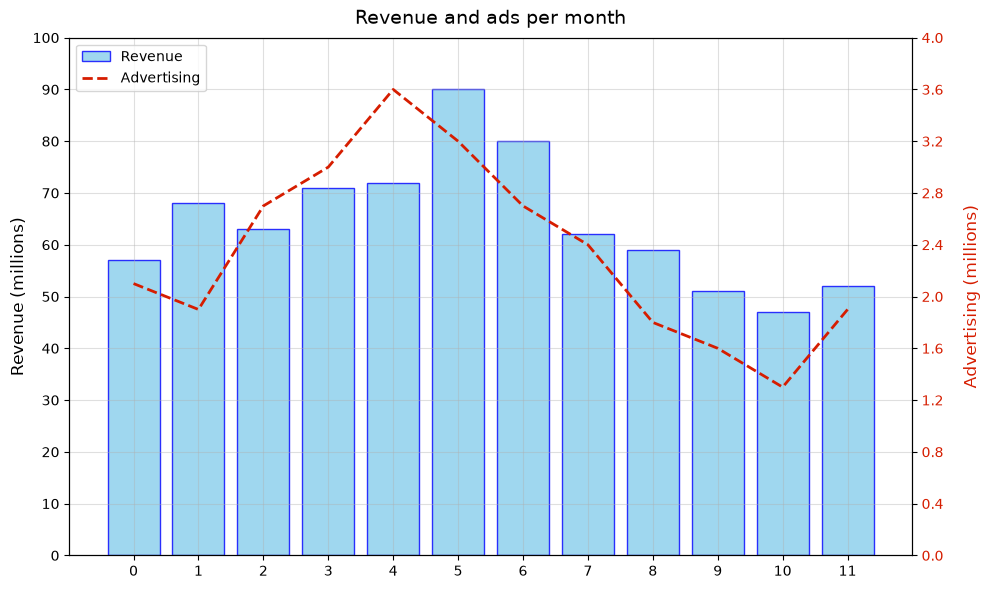

In [61]:
fig, ax = plt.subplots(1, 1, figsize=(10,6))
ax.set_title(
    'Revenue and ads per month', 
    fontsize=14,
    fontweight='normal',
    pad=10
)

ax.bar(
    df['month'], 
    df['revenue'], 
    color='skyblue', 
    alpha=0.8, 
    edgecolor='blue',
    label='Revenue'
)
ax.grid(True, alpha=0.4)
ax.set_xticks(df['month'])
ax.set_yticks(np.arange(0, df['revenue'].max() * 1.2, 10))
ax.set_ylabel('Revenue (millions)', fontsize=12)

ax_ads = ax.twinx()
ax_ads_color = "#D61D00"

ax_ads.plot(
    df['month'],
    df['advertising'],
    color=ax_ads_color,
    alpha=1,
    linewidth=2,
    linestyle='--',
    label='Advertising'
)
ax_ads.tick_params(axis='y', labelcolor=ax_ads_color)
ax_ads.set_ylim(0, 4)
ax_ads.set_yticks(np.arange(0, 4.4, 0.4))
ax_ads.set_ylabel(
    'Advertising (millions)', 
    color=ax_ads_color, 
    fontsize=12,
    labelpad=14
)

handles, labels = ax.get_legend_handles_labels()
handles_ads, labels_ads = ax_ads.get_legend_handles_labels()

ax.legend(
    handles=(handles + handles_ads),
    labels=(labels + labels_ads),
    loc='upper left'
)

fig.tight_layout()
plt.show()

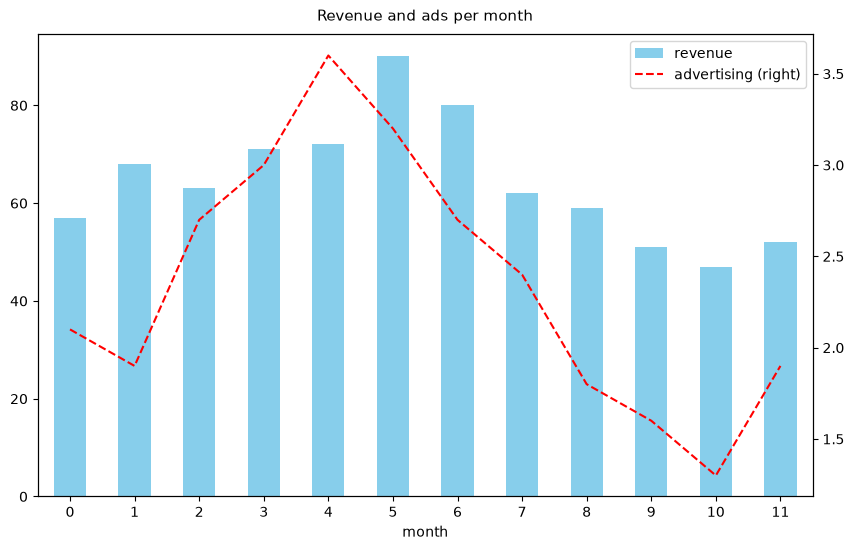

In [62]:
ax = df.plot.bar(
    'month', 
    'revenue', 
    color='skyblue',
    figsize=(10, 6)
)

df.plot.line(
    'month', 
    'advertising', 
    color='red', linestyle='--',
    ax=ax, secondary_y=True
)

plt.title(
    'Revenue and ads per month', 
    fontsize=11,
    fontweight='normal',
    pad=10
)
plt.show()

### Task 2

В DataFrame temp названия городов записаны в смешанном регистре. Нормализуйте строки так, чтобы только первая буква была заглавной: например, londON должно превратиться в London.

Предполагаются импорты import pandas as pd и import numpy as np.

In [63]:
df = pd.DataFrame({'From_To': ['LoNDon_paris', 'MAdrid_miLAN', 'londON_StockhOlm', 
                               'Budapest_PaRis', 'Brussels_londOn'],
              'FlightNumber': [10045, np.nan, 10065, np.nan, 10085],
              'RecentDelays': [[23, 47], [], [24, 43, 87], [13], [67, 32]],
                   'Airline': ['KLM(!)', '<Air France> (12)', '(British Airways. )', 
                               '12. Air France', '"Swiss Air"']})

temp = df.From_To.str.split('_', expand=True)
temp.columns = ['From', 'To']

In [64]:
df['From_To'] = df['From_To'].str.title()
df

,From_To,FlightNumber,RecentDelays,Airline
0,London_Paris,10045.0,"[23, 47]",KLM(!)
1,Madrid_Milan,NaN,[],<Air France> (12)
2,London_Stockholm,10065.0,"[24, 43, 87]",(British Airways. )
3,Budapest_Paris,NaN,[13],12. Air France
4,Brussels_London,10085.0,"[67, 32]","""Swiss Air"""


### Task 3

Выберите строки, в которых животное — кошка (cat), а возраст меньше 3.

In [65]:
data = {'animal': ['cat', 'cat', 'snake', 'dog', 'dog', 'cat', 'snake', 'cat', 'dog', 'dog'],
        'age': [2.5, 3, 0.5, np.nan, 5, 2, 4.5, np.nan, 7, 3],
        'visits': [1, 3, 2, 3, 2, 3, 1, 1, 2, 1],
        'priority': ['yes', 'yes', 'no', 'yes', 'no', 'no', 'no', 'yes', 'no', 'no']}

labels = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j']

df = pd.DataFrame(data, index=labels)

In [66]:
cond = (df['animal'] == 'cat') & (df['age'] < 3)
df[cond]

,animal,age,visits,priority
a,cat,2.5,1,yes
f,cat,2.0,3,no


### Task 4

Дан DataFrame случайных числовых значений. Как вычесть из каждого элемента среднее значение его строки?

In [67]:
df = pd.DataFrame(np.random.random(size=(5, 3)))

display(df.apply(lambda row: row - row.mean(), axis=1))

print()

display(df.sub(df.mean(axis=1), axis=0))


,0,1,2
0,0.277958,0.295884,-0.573842
1,0.101299,-0.039053,-0.062247
2,0.021563,-0.076086,0.054523
3,-0.210372,-0.240316,0.450688
4,-0.248626,0.432089,-0.183463


,0,1,2
0,0.277958,0.295884,-0.573842
1,0.101299,-0.039053,-0.062247
2,0.021563,-0.076086,0.054523
3,-0.210372,-0.240316,0.450688
4,-0.248626,0.432089,-0.183463


### Task 5

Найдите сумму значений Series s, приходящихся на среды.

In [68]:
dti = pd.date_range(start='2015-01-01', end='2015-12-31', freq='B') 
s = pd.Series(np.random.rand(len(dti)), index=dti)

In [69]:
s[s.index.day_of_week == 2].sum()

np.float64(23.994857543032794)

### Task 6

Сделайте срез Series s: на первом уровне MultiIndex выберите метки до B включительно, на втором — от 5 и далее.

In [70]:
letters = ['A', 'B', 'C']
numbers = list(range(10))

mi = pd.MultiIndex.from_product([letters, numbers])
s = pd.Series(np.random.rand(30), index=mi)

In [71]:
s.loc[pd.IndexSlice[:'B', 5:]]

# or equivalently without IndexSlice...
s.loc[slice(None, 'B'), slice(5, None)]

A  5    0.547595
   6    0.767899
   7    0.570740
   8    0.937987
   9    0.416969
B  5    0.975976
   6    0.684511
   7    0.316006
   8    0.315847
   9    0.097042
dtype: float64

### Task 7

DataFrame df содержит 10 столбцов вещественных чисел, причём в каждой строке ровно 5 пропусков NaN. Для каждой строки найдите столбец с третьим пропуском слева. Ожидается Series с метками e, c, d, h, d.

In [72]:
nan = np.nan

data = [[0.04,  nan,  nan, 0.25,  nan, 0.43, 0.71, 0.51,  nan,  nan],
        [ nan,  nan,  nan, 0.04, 0.76,  nan,  nan, 0.67, 0.76, 0.16],
        [ nan,  nan, 0.5 ,  nan, 0.31, 0.4 ,  nan,  nan, 0.24, 0.01],
        [0.49,  nan,  nan, 0.62, 0.73, 0.26, 0.85,  nan,  nan,  nan],
        [ nan,  nan, 0.41,  nan, 0.05,  nan, 0.61,  nan, 0.48, 0.68]]

columns = list('abcdefghij')

df = pd.DataFrame(data, columns=columns)
df

,a,b,c,d,e,f,g,h,i,j
0,0.04,NaN,NaN,0.25,NaN,0.43,0.71,0.51,NaN,NaN
1,NaN,NaN,NaN,0.04,0.76,NaN,NaN,0.67,0.76,0.16
2,NaN,NaN,0.50,NaN,0.31,0.40,NaN,NaN,0.24,0.01
3,0.49,NaN,NaN,0.62,0.73,0.26,0.85,NaN,NaN,NaN
4,NaN,NaN,0.41,NaN,0.05,NaN,0.61,NaN,0.48,0.68


In [73]:
def get_third_nan(s):
    numered_nans = np.cumsum(np.isnan(s)) * np.isnan(s)
    return s[numered_nans == 3].index[0]

df.apply(get_third_nan, axis=1)

0    e
1    c
2    d
3    h
4    d
dtype: str

In [74]:
(df.isna().cumsum(axis=1) == 3).idxmax(axis=1)

0    e
1    c
2    d
3    h
4    d
dtype: str

### Task 8

Вычислите средний возраст для каждого вида животных в df.

In [75]:
data = {'animal': ['cat', 'cat', 'snake', 'dog', 'dog', 'cat', 'snake', 'cat', 'dog', 'dog'],
        'age': [2.5, 3, 0.5, np.nan, 5, 2, 4.5, np.nan, 7, 3],
        'visits': [1, 3, 2, 3, 2, 3, 1, 1, 2, 1],
        'priority': ['yes', 'yes', 'no', 'yes', 'no', 'no', 'no', 'yes', 'no', 'no']}

labels = ['a', 'b', 'c', 'd', 'e', 'f', 'g', 'h', 'i', 'j']

df = pd.DataFrame(data, index=labels)

In [76]:
df.groupby('animal', as_index=True)['age'].mean()

animal
cat      2.5
dog      5.0
snake    2.5
Name: age, dtype: float64